# PBISC manuscript metrics — 데모 (합성 데이터)

gene-mean 곡선 · iLISI · composition / within-type 분해 · 희귀세포 통계를 `pbisc_metrics`로 계산하는 예제입니다.

**주의:** 이 노트북의 숫자는 **합성 코호트**(알려진 정답이 있는 시뮬레이션)에서 나온 것으로, 각 지표가 올바르게 작동하는지 확인하기 위한 것입니다. PBISC 논문 수치가 아닙니다.
- `real_A`: 참조(real A), `real_B`: 독립 환자의 real 대조(상한), `generated`: 의도적으로 결함을 넣은 생성본 (질병 효과 60–70%로 약화, 희귀 상태 `NK_bright` 소실, 깊이 낮음, 저발현 유전자 절벽).
- 실제 데이터는 마지막 셀의 패턴대로 `.h5ad`를 읽어 같은 함수에 넣으면 됩니다.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from pbisc_metrics import gene_mean as gm, ilisi as il, decomposition as dc, rare_stats as rs, synthetic as S

world = S.make_world(n_genes=600, seed=0)
real_a = S.sample_cohort(world, n_per_group=14, seed=1, prefix="a")
real_b = S.sample_cohort(world, n_per_group=14, seed=2, prefix="b")
gen    = S.sample_cohort(world, n_per_group=14, seed=7, comp_scale=0.7, within_scale=0.6,
                         drop_fine=("NK_bright",), depth_mean=1200, lowexpr_floor=0.5, prefix="g")
for n, c in [("real_A", real_a), ("real_B", real_b), ("generated", gen)]:
    print(f"{n:10s} cells {c['X'].shape[0]:>6,}  genes {c['X'].shape[1]}  median UMI/cell {np.median(np.asarray(c['X'].sum(1)).ravel()):.0f}")

real_A     cells 11,200  genes 600  median UMI/cell 1483
real_B     cells 11,200  genes 600  median UMI/cell 1515
generated  cells 11,200  genes 600  median UMI/cell 1140


## 1. gene-mean 곡선

유전자별 평균 UMI/CP10k, real 순위 구간별 generated/real 비, real을 생성본 깊이로 binomial thinning한 depth-matched 대조.

In [2]:
t = gm.compare_gene_means(real_a["X"], real_a["genes"], gen["X"], gen["genes"], depth_match=True)
print(pd.Series(gm.correlation_summary(t)).round(4).to_string())
print()
print("순위 구간별 (ratio = Σgen CP10k / Σreal CP10k, det_ratio = 검출률 비)")
display(gm.band_table(t, by="rank", edges=(0, 100, 200, 300, 400, np.inf)).round(3))

n_genes                                  600.0000
pearson_log1p_cp10k                        0.9887
spearman_cp10k                             0.9946
pearson_detection                          0.9853
genes_never_generated                     45.0000
genes_never_in_real                        0.0000
pearson_log1p_cp10k_depthmatched_real      1.0000

순위 구간별 (ratio = Σgen CP10k / Σreal CP10k, det_ratio = 검출률 비)


,band,n_genes,real_mean_cp10k,gen_mean_cp10k,ratio,median_ratio,det_ratio,never_generated,dm_real_ratio
0,0-100,100,70.675,73.965,1.047,1.057,0.970,0,1.000
1,100-200,100,15.368,15.904,1.035,1.050,0.892,0,1.000
2,200-300,100,7.549,7.084,0.938,0.942,0.766,0,1.000
3,300-400,100,3.783,2.513,0.664,0.655,0.536,0,1.001
4,400-inf,200,1.312,0.267,0.204,0.063,0.165,45,0.999


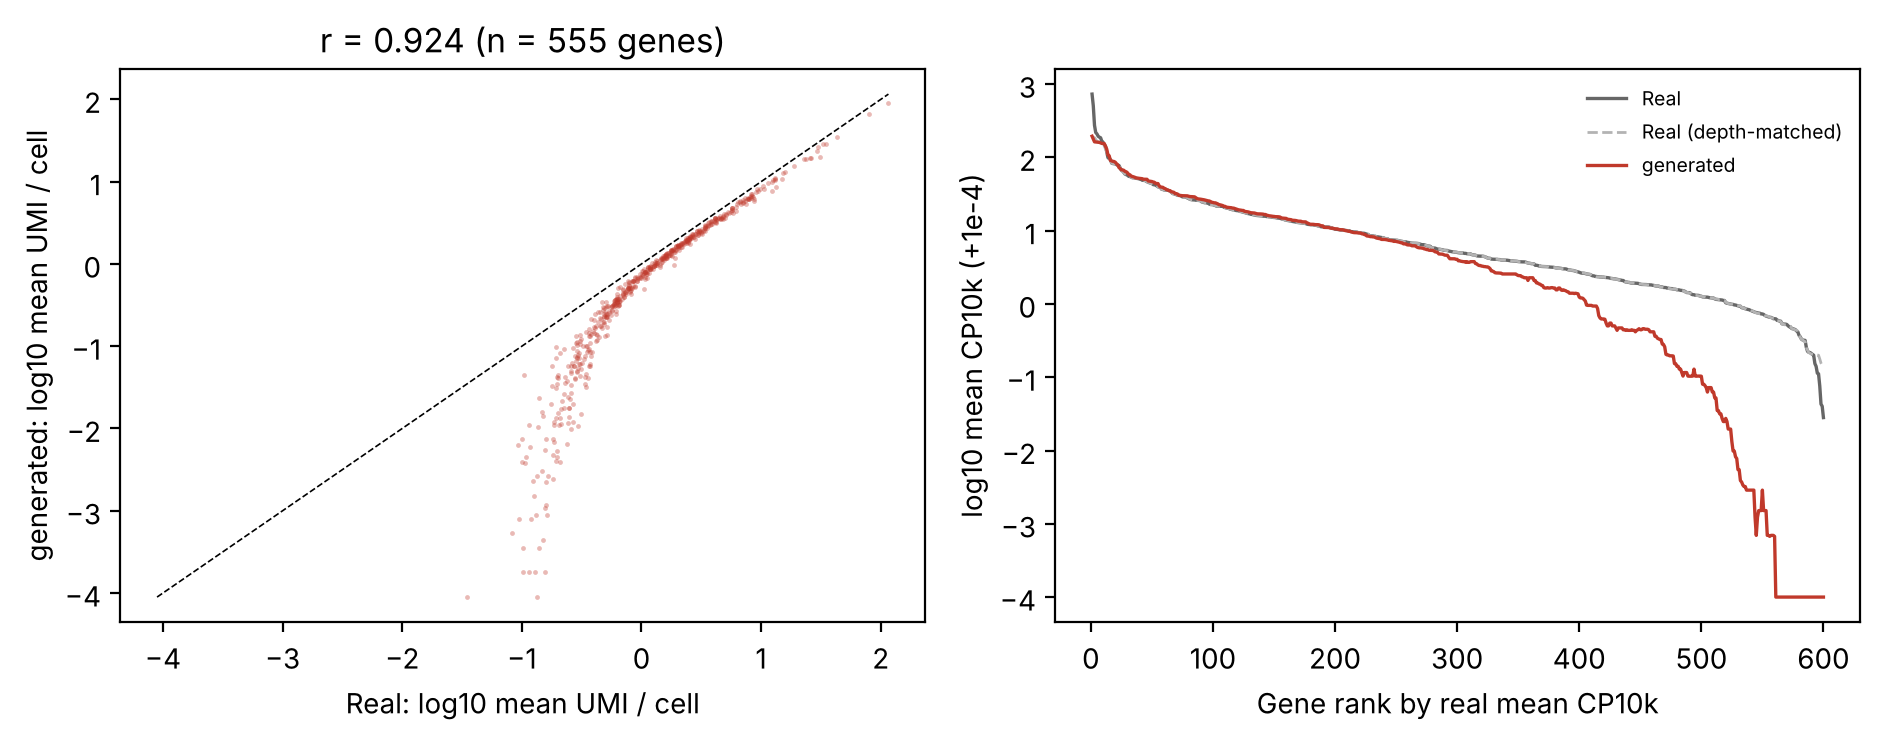

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
gm.plot_gene_mean_scatter(ax[0], t, label="generated")
gm.plot_gene_mean_curve(ax[1], t, label="generated", smooth=25)
plt.tight_layout(); plt.show()

## 2. iLISI (pairwise Harmony)

참조 real A 대비 real B(상한)와 생성본. `fraction_of_ceiling = (iLISI − 1)/(iLISI_ceiling − 1)`; 상한은 2.

In [4]:
rep = il.ilisi_report(real_a["X"], real_a["genes"],
        {"real_B": (real_b["X"], real_b["genes"], real_b["obs"].patient.to_numpy()),
         "generated": (gen["X"], gen["genes"], gen["obs"].patient.to_numpy())},
        ceiling="real_B", ref_patient=real_a["obs"].patient.to_numpy(),
        n_per_source=5000, n_hvg=300, n_pcs=20, n_draws=3, n_boot=300)
display(rep.round(3))

,n_per_source,n_hvg,ilisi_pre,own_share_pre,ilisi_post,own_share_post,ilisi_post_boot_median,ilisi_post_ci_lo,ilisi_post_ci_hi,fraction_of_ceiling_pre,fraction_of_ceiling_post
source,,,,,,,,,,,
real_B,5000,300,1.758,0.513,1.765,0.510,1.765,1.713,1.817,1.000,1.000
generated,5000,300,1.050,0.778,1.261,0.598,1.261,1.023,1.890,0.066,0.341


## 3. composition / within-type 분해

질병(case − control) 효과를 `total = composition + within`으로 나누고(합 정확히 일치), real을 환자 단위 split-half(200회)로 잡음 보정한 slope와 disattenuated r로 평가. 생성본의 정답 약화는 조성·within 모두 0.7 / 0.6입니다.

In [5]:
def agg(c):
    meta = c["obs"].drop_duplicates("sample").set_index("sample")[["group", "patient"]]
    return dc.aggregate(c["X"], c["genes"], c["obs"]["sample"], c["obs"]["parent"], meta)
A_real, A_gen = agg(real_a), agg(gen)
slopes, eff_real, eff_gen, dprop = dc.decomposition_report(A_real, A_gen, "case", "control", n_splits=200, seed=0)
print("분해 항등식 최대 오차:", float((eff_gen.composition + eff_gen.within - eff_gen.total).abs().max()))
display(slopes.round(3))
display(dprop.round(2))

분해 항등식 최대 오차: 2.842170943040401e-14


,slope,slope_sd,split_cv,r_dis,r_dis_sd,reliability,n_splits_used
effect,,,,,,,
total,0.628,0.062,0.099,0.989,0.010,0.960,200
composition,0.729,0.080,0.110,0.996,0.010,0.984,200
within,0.545,0.034,0.063,0.948,0.037,0.926,200
type:B,0.440,0.026,0.059,0.948,0.018,0.928,200
type:Mono,0.560,0.087,0.155,0.894,0.093,0.880,200
type:NK,0.726,0.035,0.049,0.896,0.041,0.894,200
type:T,0.519,0.021,0.041,0.963,0.011,0.954,200


,real_pp,generated_pp
B,-4.88,-4.30
Mono,26.57,17.87
NK,-3.96,-3.89
T,-17.73,-9.68


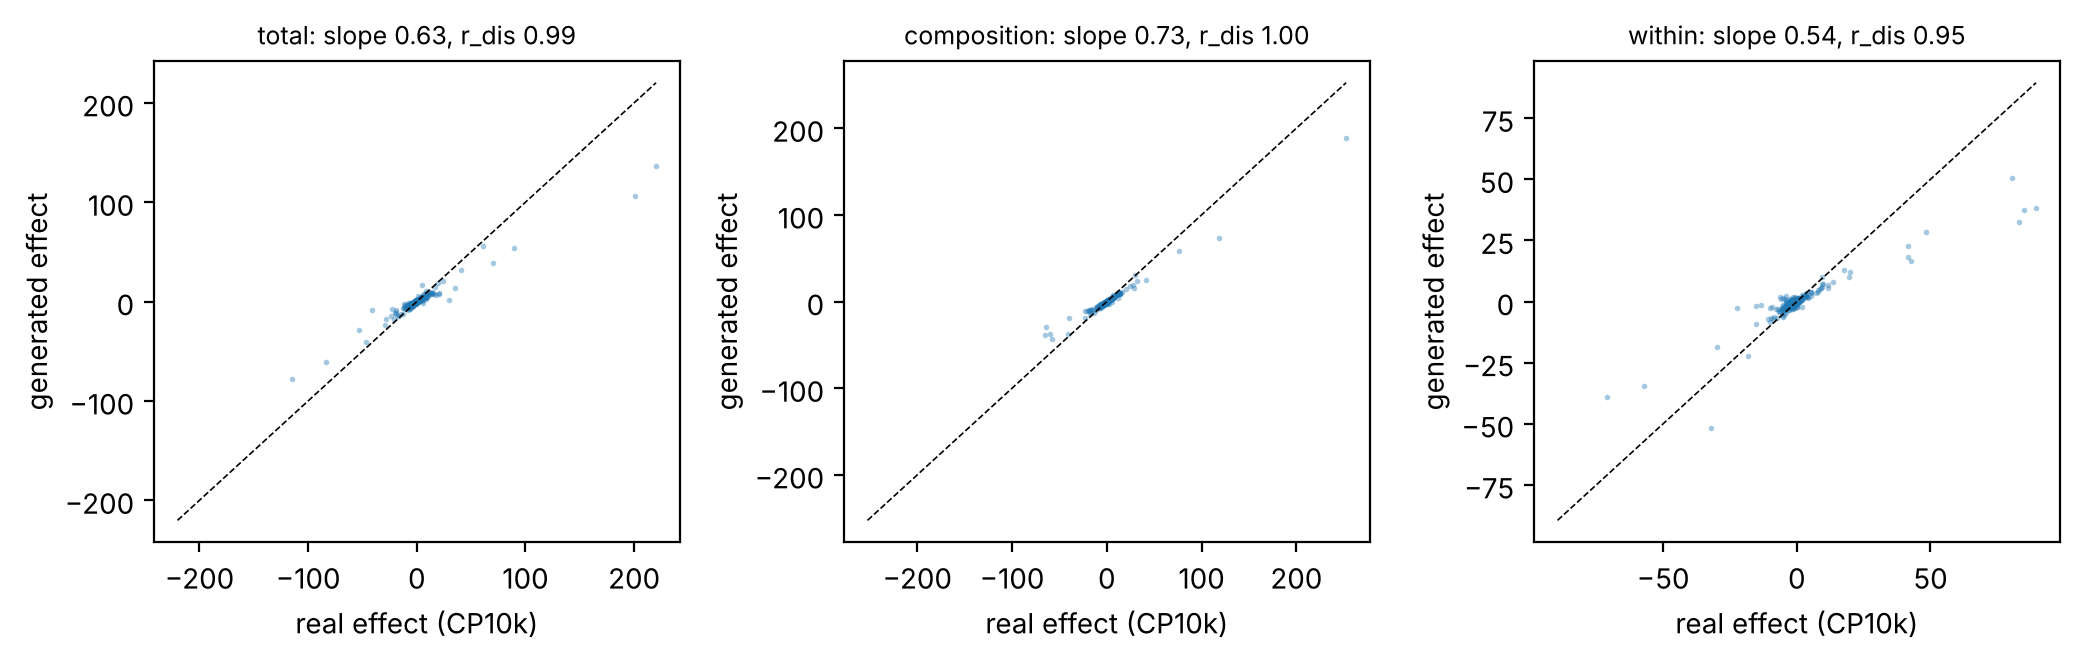

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.4))
for a, k in zip(ax, ["total", "composition", "within"]):
    a.scatter(eff_real[k], eff_gen[k], s=4, alpha=.4, linewidths=0)
    lim = np.abs(eff_real[k]).max(); a.plot([-lim, lim], [-lim, lim], "k--", lw=.6)
    a.set_title(f"{k}: slope {slopes.loc[k,'slope']:.2f}, r_dis {slopes.loc[k,'r_dis']:.2f}", fontsize=9)
    a.set_xlabel("real effect (CP10k)"); a.set_ylabel("generated effect")
plt.tight_layout(); plt.show()

## 4. 희귀세포 통계

parent lineage 안에서의 fine label 비율(share), real A 대비 비(ratio), 판정(0.5× 미만 / 0.5–2× / 2× 초과), 환자 bootstrap 95% CI. real B로 같은 비(ceiling)도 함께 봅니다.

In [7]:
rt = rs.rare_table(real_a["obs"], gen["obs"], obs_ctrl=real_b["obs"], rare_threshold=0.1, n_boot=1000, seed=0)
cols = ["fine", "parent", "n_ref", "n_gen", "share_ref", "share_gen", "ratio", "ratio_ci_lo", "ratio_ci_hi", "ratio_ctrl",
        "is_rare", "low_n", "gen_samples_detected", "p_miss_per_sample", "verdict"]
display(rt[cols].round(3))
print(rs.verdict_summary(rt).to_string())

,fine,parent,n_ref,n_gen,share_ref,share_gen,ratio,ratio_ci_lo,ratio_ci_hi,ratio_ctrl,is_rare,low_n,gen_samples_detected,p_miss_per_sample,verdict
0,B_naive,B,1443,1497,1.000,1.000,1.000,1.000,1.000,1.000,False,False,28,0.000,recovered
1,Mono_classical,Mono,3969,3711,0.948,0.947,0.999,0.989,1.007,1.001,False,False,28,0.000,recovered
2,Mono_inflam,Mono,217,208,0.052,0.053,1.024,0.873,1.219,0.990,True,False,28,0.000,recovered
3,NK_bright,NK,90,0,0.072,0.000,0.000,0.000,0.000,0.843,True,True,0,0.040,below
4,NK_dim,NK,1166,1328,0.928,1.000,1.077,1.066,1.089,1.012,False,False,28,0.000,recovered
5,T_cyc,T,130,149,0.030,0.033,1.110,0.878,1.409,0.932,True,False,28,0.009,recovered
6,T_naive,T,4185,4307,0.970,0.967,0.997,0.989,1.004,1.002,False,False,28,0.000,recovered


verdict
recovered         2
below             1
over              0
not_assessable    0


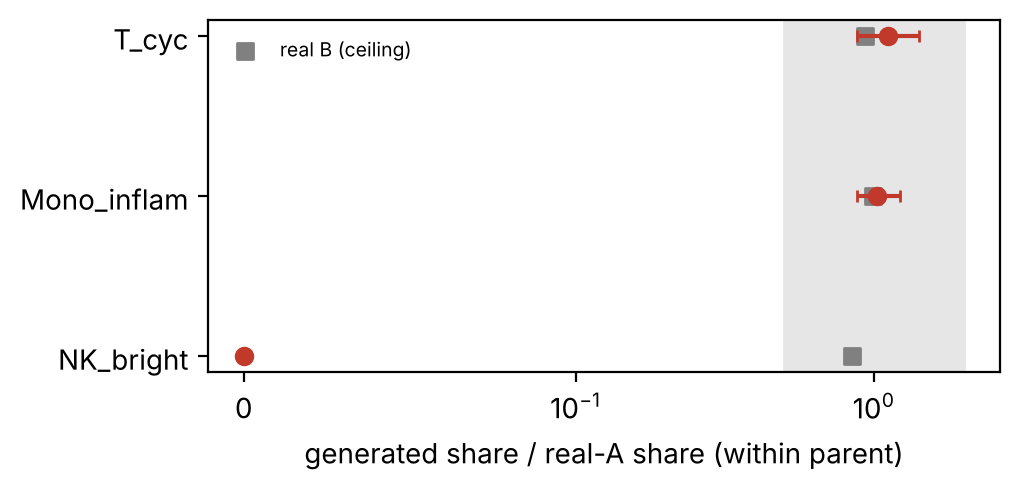

In [8]:
r = rt[rt.is_rare | (rt.ratio < 0.5)].sort_values("ratio")
fig, ax = plt.subplots(figsize=(5.2, 0.45 * len(r) + 1.2))
y = np.arange(len(r)); ax.errorbar(r.ratio, y, xerr=[r.ratio - r.ratio_ci_lo, r.ratio_ci_hi - r.ratio], fmt="o", color="#c0392b", capsize=2)
ax.scatter(r.ratio_ctrl, y, marker="s", color="0.5", label="real B (ceiling)", zorder=0)
ax.axvspan(0.5, 2, color="0.9", zorder=-1); ax.set_xscale("symlog", linthresh=0.1); ax.set_yticks(y); ax.set_yticklabels(r.fine)
ax.set_xlabel("generated share / real-A share (within parent)"); ax.legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()

## 실제 데이터에 적용하는 패턴

```python
import anndata as ad
real_A = ad.read_h5ad("real_A.h5ad"); gen = ad.read_h5ad("pbisc_ceiling_annotated.h5ad")   # counts: X 또는 layers["counts"]

# 1) gene-mean
t = gm.compare_gene_means(real_A.X, real_A.var_names, gen.X, gen.var_names)
# 2) iLISI (real B = 독립 환자 real, ceiling)
rep = il.ilisi_report(real_A.X, real_A.var_names, {"real_B": (real_B.X, real_B.var_names, real_B.obs.donor_id),
                      "PBISC": (gen.X, gen.var_names, gen.obs.donor_id)}, ceiling="real_B", ref_patient=real_A.obs.donor_id, n_boot=1000)
# 3) 분해: obs에 sample / celltype_broad, 샘플 메타(group, patient) 필요
# 4) 희귀: obs에 patient, sample, 'fine'(celltype_fine), 'parent'(celltype_broad 또는 celltype_major)
```
유전자 중복 심볼(sepsis 6, COVID 4개)은 `align_genes`가 첫 번째만 남깁니다. 큰 코호트의 iLISI는 `n_per_source=20000` 권장.